# Final Project: Willingness to Pay for School Quality
**ECON 570 Final Project**

**Team Number:** 31  
**Principal Investigators:** Kyle Poage (kpoage@wisc.edu), Harshit Goyal (hgoyal7@wisc.edu), Bobby Bui (hhbui2@wisc.edu), Abhay Mettu (mettu@wisc.edu)

This notebook analyzes the relationship between school quality (measured by Overall Accountability Score) and average home prices. We address potential omitted variable bias by controlling for demographic and economic characteristics of the school districts.


In [50]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.formula.api as smf

# Set plot style
sns.set_theme(style="whitegrid")

### 1. Data Loading and Cleaning
First, we load the Zillow Home Value Index data and filter for the year 2024. We aggregate the home values to the City level.

In [51]:
# Load Zillow data
houses = pd.read_csv('data/Zip_zhvi_uc_sfrcondo_tier_0.33_0.67_sm_sa_month.csv')

# Melt into long format
zillow_long = houses.melt(
    id_vars=['RegionID', 'SizeRank', 'RegionName', 'RegionType',
             'StateName', 'State', 'City', 'Metro', 'CountyName'],
    var_name='Date', value_name='HomeValue')

zillow_long['Date'] = pd.to_datetime(zillow_long['Date'])

# Filter to recent data (2024) and Wisconsin (WI)
zillow_recent = zillow_long[(zillow_long['Date'].dt.year == 2024) & (zillow_long['State'] == 'WI')]

# Group by City to match the school district data
zillow_city = zillow_recent.groupby('City')['HomeValue'].mean().reset_index()
print(f"{len(zillow_city)} cities with 2024 home values loaded.")

572 cities with 2024 home values loaded.


Next, we load the District Report Card Data. We restrict the data to the District level to ensure our unit of observation matches.

In [52]:
# Load Schools data
df_schools = pd.read_excel('data/2024-25_district_reportcard_data.xlsx', sheet_name='Data')

# Filter to District level only to avoid duplicating cities across schools
df_schools = df_schools[df_schools['Report Card Level'] == 'District']

# Select relevant columns for our analysis, including covariates to prevent omitted variable bias
cols_to_keep = [
    'City', 'Overall Accountability Score', 
    'Percent Economically Disadvantaged', 
    'Percent White', 'Percent Students with Disabilities'
]
df_schools = df_schools[cols_to_keep].copy()

# Convert columns to numeric, coercing errors to NaN
for col in cols_to_keep[1:]:
    df_schools[col] = pd.to_numeric(df_schools[col], errors='coerce')
    
df_schools = df_schools.dropna()
print(f"{len(df_schools)} districts retained after cleaning.")

378 districts retained after cleaning.


We merge the two datasets using an inner join on `City`.

In [53]:
# Merge Zillow and School data
merged = pd.merge(df_schools, zillow_city, on='City', how='inner')

# Rename columns to avoid issues in statsmodels formulas
merged = merged.rename(columns={
    'Overall Accountability Score': 'Score',
    'Percent Economically Disadvantaged': 'Econ_Disadv',
    'Percent White': 'Pct_White',
    'Percent Students with Disabilities': 'Pct_Disabilities'
})

print(f"{len(merged)} observations in the final merged dataset.")
merged.head()

326 observations in the final merged dataset.


,City,Score,Econ_Disadv,Pct_White,Pct_Disabilities,HomeValue
0,Cedarburg,95.4,0.088,0.893,0.113,485618.434520
1,Cudahy,59.9,0.626,0.490,0.198,255992.784768
2,Brookfield,89.0,0.091,0.688,0.114,468510.553080
3,Franklin,78.1,0.223,0.663,0.097,402922.855440
4,Germantown,81.6,0.146,0.776,0.128,405370.653725


### 2. Exploratory Data Analysis
We visualize the unconditional relationship between school quality and home values. We observe a positive correlation.

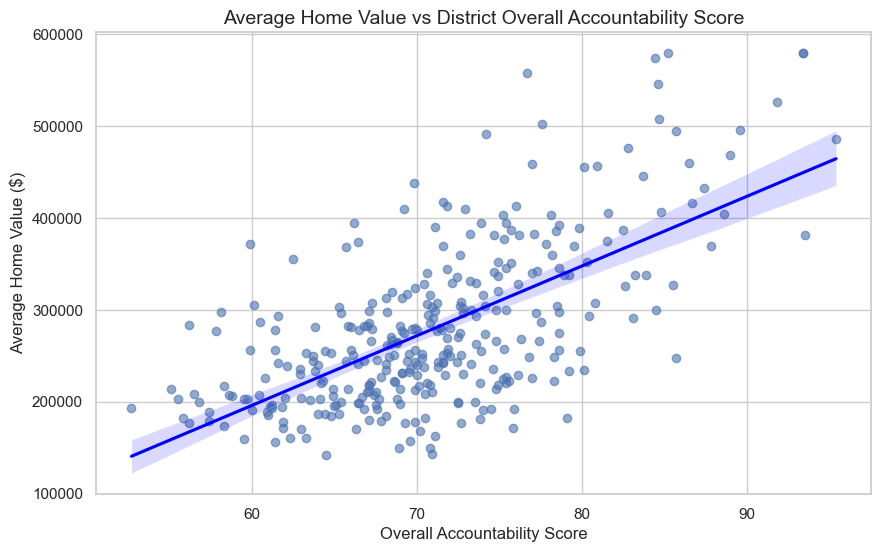

In [54]:
plt.figure(figsize=(10, 6))
sns.regplot(data=merged, x='Score', y='HomeValue', scatter_kws={'alpha':0.6}, line_kws={'color':'blue'})
plt.title('Average Home Value vs District Overall Accountability Score', fontsize=14)
plt.xlabel('Overall Accountability Score', fontsize=12)
plt.ylabel('Average Home Value ($)', fontsize=12)
plt.show()

We also visualize the relationship between the percent of economically disadvantaged students and home values, demonstrating a strong negative relationship. This implies that income is correlated with home values, and likely also with school quality, presenting a source of omitted variable bias.

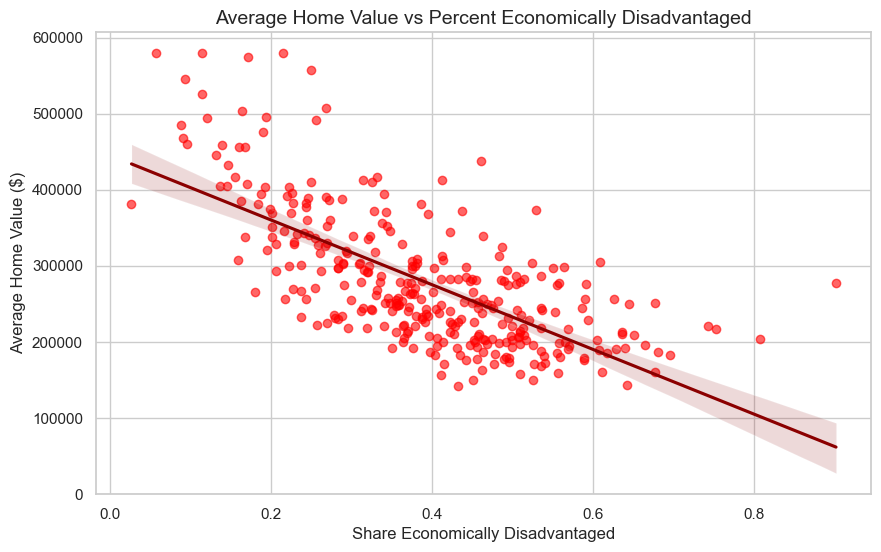

In [55]:
plt.figure(figsize=(10, 6))
sns.regplot(data=merged, x='Econ_Disadv', y='HomeValue', scatter_kws={'alpha':0.6}, color='red', line_kws={'color':'darkred'})
plt.title('Average Home Value vs Percent Economically Disadvantaged', fontsize=14)
plt.xlabel('Share Economically Disadvantaged', fontsize=12)
plt.ylabel('Average Home Value ($)', fontsize=12)
plt.show()

### 3. Regression Analysis
We begin with a naive model regressing Home Value solely on the Accountability Score.

In [56]:
naive_model = smf.ols('HomeValue ~ Score', data=merged).fit()
print(naive_model.summary())

                            OLS Regression Results                            
Dep. Variable:              HomeValue   R-squared:                       0.421
Model:                            OLS   Adj. R-squared:                  0.419
Method:                 Least Squares   F-statistic:                     235.6
Date:                Wed, 29 Apr 2026   Prob (F-statistic):           2.43e-40
Time:                        17:56:37   Log-Likelihood:                -4086.0
No. Observations:                 326   AIC:                             8176.
Df Residuals:                     324   BIC:                             8184.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept  -2.589e+05   3.53e+04     -7.338      0.0

Now, we introduce controls to address omitted variable bias. We control for economic disadvantage, racial demographics, and disability percentages.

In [57]:
extended_model = smf.ols('HomeValue ~ Score + Econ_Disadv + Pct_White + Pct_Disabilities', data=merged).fit()
print(extended_model.summary())

                            OLS Regression Results                            
Dep. Variable:              HomeValue   R-squared:                       0.631
Model:                            OLS   Adj. R-squared:                  0.627
Method:                 Least Squares   F-statistic:                     137.4
Date:                Wed, 29 Apr 2026   Prob (F-statistic):           2.92e-68
Time:                        17:56:38   Log-Likelihood:                -4012.5
No. Observations:                 326   AIC:                             8035.
Df Residuals:                     321   BIC:                             8054.
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept         3.711e+05   5.97e+04  

**Conclusion of Analysis:**
The naive model suggests that a one-point increase in a district's accountability score is associated with a 7,584 dollar increase in average home values. However, after controlling for demographic and socioeconomic differences—most notably the percent of economically disadvantaged students—this premium drops by over 50% to 3,307 dollars. This confirms that the naive estimate suffered severely from omitted variable bias. While our model controls for key socioeconomic confounders, we acknowledge that these estimates may still suffer from unobserved heterogeneity, such as localized property tax rates or residential sorting, precluding a strictly causal interpretation. Nonetheless, the substantial reduction in the coefficient underscores the critical importance of causal inference techniques and appropriate controls when evaluating policy-relevant economic questions.